# Couvrir un paiement en dollars : ce que coûte vraiment un forward FX

**Palier :** 1 — Marchés et produits
**Niveau :** Accessible
**Durée cible :** 9-10 min (format court)
**Prérequis :** P0-6 (no-arbitrage), P0-7 (actualisation)

---
> Support de présentation de la vidéo. Entièrement exécuté avant le tournage.
> Les taux et cours sont **construits pour la pédagogie**, ce ne sont pas des cotations de marché.

## 1. Question

> Une entreprise européenne va encaisser 1 million de dollars dans 6 mois. Elle veut figer aujourd'hui le montant en euros. À quel cours ? Et pourquoi ce cours n'est-il **pas** celui d'aujourd'hui ?

## 2. Intuition

Figer un cours à terme, c'est **vendre aujourd'hui des dollars qu'on recevra plus tard**. La banque, qui prend l'autre côté, ne parie pas sur le cours futur : elle se couvre en empruntant, en convertissant et en plaçant (c'est le raisonnement du no-arbitrage de la vidéo précédente). Ce que ça lui coûte ou lui rapporte dépend uniquement de l'écart entre les taux dollar et euro. Cet écart, converti en différence de prix, s'appelle les **points de terme** (*forward points*).

### Glossaire

| Terme | Définition simple |
|---|---|
| **Spot** | Échange de devises au cours du jour, mais **dénoué (livré) 2 jours ouvrés plus tard** (T+2) pour la plupart des paires. |
| **Date de valeur** | Date à laquelle l'argent change effectivement de mains. |
| **Forward** | Échange à une date de valeur plus lointaine, à un cours fixé aujourd'hui. |
| **Points de terme** | Différence entre le cours forward et le cours spot, exprimée en *pips*. |
| **Pip** | 0,0001 pour EURUSD (4e décimale). |
| **Prime / décote** | Une devise est « à prime » à terme si son forward est plus élevé que le spot ; « à décote » sinon. |
| **Couverture** (*hedge*) | Opération qui supprime un risque, ici le risque de change. |

## 3. Hypothèses

1. Taux **monétaires simples**, base **Act/360** pour l'EUR et l'USD (convention des dépôts interbancaires, Hull §6.1).
2. Pas de coûts de transaction dans la formule, sauf dans l'expérience 8.3 où on ajoute un bid/offer sur les points.
3. Le calendrier suit les jours ouvrés simples (jours fériés ignorés).
4. Pas de cross-currency basis : on utilise un seul taux par devise (voir Limites).

## 4. Notation

| Symbole | Signification |
|---|---|
| $S$ | cours spot EURUSD = nombre de **dollars pour 1 euro** |
| $F$ | cours forward EURUSD |
| $r_{USD}, r_{EUR}$ | taux monétaires simples annuels |
| $d$ | nombre de jours entre la date de valeur spot et la date de valeur forward |
| $\tau = d/360$ | durée en fraction d'année Act/360 |
| $N$ | montant en dollars à couvrir |

## 5. Mathématiques

### 5.1 Le cours forward
$$F = S\,\frac{1+r_{USD}\,\tau}{1+r_{EUR}\,\tau}$$

Lecture : le numérateur est ce que rapporte un placement en dollars pendant $\tau$ ; le dénominateur, ce que rapporte un placement en euros. Si le dollar rapporte plus que l'euro ($r_{USD}>r_{EUR}$), alors $F>S$ : il faut **plus de dollars** pour acheter 1 euro à terme.

**Pourquoi ?** Par no-arbitrage : placer des dollars, ou les convertir en euros au spot et placer ces euros en gardant la possibilité de les reconvertir à terme, doit donner le même résultat. Ce n'est pas une prévision du cours futur.

### 5.2 Les points de terme
$$\text{points} = (F-S)\times 10\,000 \quad \text{(en pips pour EURUSD)}$$

### 5.3 Valeur en euros d'une couverture
Une entreprise qui reçoit $N$ dollars et les vend à terme à $F$ obtient
$$\frac{N}{F} \text{ euros}$$
Si elle ne couvre pas, elle obtient $N/S_T$ euros, où $S_T$ est le cours le jour où elle encaisse (inconnu aujourd'hui).

## 6. Implémentation

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["font.size"] = 12

### 6.1 Les dates : spot à T+2, puis le forward 6 mois

On part d'un jour de transaction, on avance de 2 jours ouvrés pour le spot, puis on compte les jours jusqu'à la date de valeur du forward.

In [2]:
trade = np.datetime64("2026-10-19")           # lundi
spot_value = np.busday_offset(trade, 2, roll="forward")   # +2 jours ouvrés
fwd_value = np.busday_offset(np.datetime64("2027-04-21"), 0, roll="forward")
d = int((fwd_value - spot_value).astype(int))
print("Date de valeur spot   :", spot_value)
print("Date de valeur forward:", fwd_value)
print("Nombre de jours d     :", d)

Date de valeur spot   : 2026-10-21
Date de valeur forward: 2027-04-21
Nombre de jours d     : 182


**Lecture :** le spot du lundi 19 octobre se dénoue le mercredi 21. Le forward 6 mois est compté **à partir de la date de valeur spot**, pas à partir du jour de transaction : 182 jours ici.

### 6.2 Le forward et les points de terme

In [3]:
def forward_fx(S, r_usd, r_eur, d, base=360):
    tau = d / base
    return S * (1 + r_usd * tau) / (1 + r_eur * tau)

def points_de_terme(S, F):
    return (F - S) * 1e4

S, r_usd, r_eur = 1.0800, 0.04, 0.02
F = forward_fx(S, r_usd, r_eur, d)
print(f"Spot    : {S:.4f}")
print(f"Forward : {F:.4f}")
print(f"Points  : {points_de_terme(S, F):+.1f} pips")

Spot    : 1.0800
Forward : 1.0908
Points  : +108.1 pips


**Lecture :** le dollar rapporte 4 %, l'euro 2 % : l'euro est **à prime** à terme (+108 pips). Ce n'est pas le marché qui « pense » que l'euro va monter, c'est l'écart de taux qui est converti en prix.

### 6.3 Vérification par réplication

On refait le calcul par un autre chemin : on place aujourd'hui l'équivalent en euros de la valeur actuelle des dollars, et on regarde combien d'euros on a dans 6 mois. Si $F$ est juste, on doit retomber sur le même montant que la couverture.

In [4]:
N = 1_000_000  # dollars à recevoir dans 6 mois
tau = d / 360

# Chemin A : vendre les dollars à terme au cours F
eur_forward = N / F

# Chemin B : réplication synthétique
usd_aujourdhui = N / (1 + r_usd * tau)   # dollars à emprunter aujourd'hui
eur_aujourdhui = usd_aujourdhui / S      # convertis en euros au spot
eur_dans_6m = eur_aujourdhui * (1 + r_eur * tau)   # placés en euros

print(f"Chemin A (forward)       : {eur_forward:,.2f} EUR")
print(f"Chemin B (réplication)   : {eur_dans_6m:,.2f} EUR")
print(f"Écart                    : {abs(eur_forward - eur_dans_6m):.6f}")

Chemin A (forward)       : 916,749.36 EUR
Chemin B (réplication)   : 916,749.36 EUR
Écart                    : 0.000000


**Lecture :** les deux chemins coïncident à la précision de la machine. C'est le no-arbitrage en action : le forward n'est que le résultat d'une réplication.

## 7. Visualisation

**Graphique — Que se passe-t-il selon le cours EURUSD le jour de l'encaissement ?**

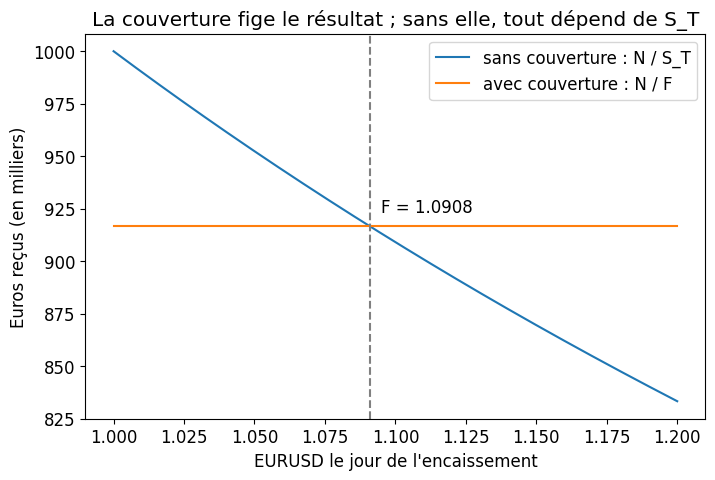

In [5]:
S_T = np.linspace(1.00, 1.20, 200)
sans_couverture = N / S_T
avec_couverture = np.full_like(S_T, N / F)

fig, ax = plt.subplots()
ax.plot(S_T, sans_couverture / 1e3, label="sans couverture : N / S_T")
ax.plot(S_T, avec_couverture / 1e3, label="avec couverture : N / F")
ax.axvline(F, color="grey", ls="--")
ax.annotate(f"F = {F:.4f}", (F, N / F / 1e3), textcoords="offset points", xytext=(8, 10))
ax.set_xlabel("EURUSD le jour de l'encaissement")
ax.set_ylabel("Euros reçus (en milliers)")
ax.set_title("La couverture fige le résultat ; sans elle, tout dépend de S_T")
ax.legend(); plt.show()

**Lecture :** la ligne plate est la couverture : on sait aujourd'hui combien d'euros on recevra. La courbe est le résultat sans couverture. À gauche de $F$ (dollar plus fort), ne pas couvrir aurait rapporté plus ; à droite (dollar plus faible), la couverture a protégé. Le point de croisement est exactement $F$.

## 8. Expériences

### 8.1 Combien coûte la couverture par rapport au spot d'aujourd'hui ?

In [6]:
eur_spot = N / S
cout = eur_spot - eur_forward
print(f"Euros au cours spot d'aujourd'hui : {eur_spot:,.0f}")
print(f"Euros avec le forward             : {eur_forward:,.0f}")
print(f"Différence                        : {cout:,.0f} EUR ({cout / eur_spot:.2%})")

Euros au cours spot d'aujourd'hui : 925,926
Euros avec le forward             : 916,749
Différence                        : 9,177 EUR (0.99%)


**Lecture :** la différence (environ 1 %) n'est pas une commission cachée : c'est l'écart de taux sur 6 mois (4 % - 2 %, soit 1 % par semestre). Pour cette entreprise, qui a une trésorerie en euros, couvrir revient à renoncer au rendement supérieur du dollar. Attention : ce n'est pas une « perte » par rapport à un cours spot qu'elle n'aurait pas pu obtenir (elle ne reçoit les dollars que dans 6 mois) ; c'est le prix du temps, comme dans la vidéo sur l'actualisation.

### 8.2 Et si on utilise la formule continue de la vidéo 3 ?

Dans la vidéo sur le no-arbitrage, on avait $F=Se^{(r-r_f)T}$. Le marché des changes cote pourtant à partir de taux **simples** Act/360. Quelle différence cela fait-il ?

In [7]:
F_cont = S * np.exp((r_usd - r_eur) * tau)
print(f"F taux simples Act/360 : {F:.5f}")
print(f"F formule continue     : {F_cont:.5f}")
print(f"Écart                  : {(F_cont - F) * 1e4:.2f} pips")
print(f"Impact sur 1 M USD     : {abs(N / F - N / F_cont):,.0f} EUR")

F taux simples Act/360 : 1.09081
F formule continue     : 1.09098
Écart                  : 1.65 pips
Impact sur 1 M USD     : 138 EUR


**Lecture :** l'écart est petit (1,6 pip), mais il n'est pas nul. Utiliser la mauvaise convention de taux, c'est introduire une erreur de prix qu'aucune stratégie de marché ne justifie. Sur un desk, la convention fait partie du prix.

### 8.3 Le bid/offer sur les points

Les points sont cotés avec un écart acheteur/vendeur. On suppose ici (valeur **hypothétique**) un écart de 1 pip sur les points.

In [8]:
spread_pips = 1.0
for notionnel in [1e6, 100e6]:
    impact = notionnel * spread_pips * 1e-4 / F**2
    print(f"Notionnel {notionnel / 1e6:>5.0f} M USD : 1 pip d'écart sur les points = {impact:,.0f} EUR")

Notionnel     1 M USD : 1 pip d'écart sur les points = 84 EUR
Notionnel   100 M USD : 1 pip d'écart sur les points = 8,404 EUR


**Lecture :** à 1 M USD, 1 pip pèse environ 84 € ; à 100 M USD, environ 8 400 €. L'écart de cotation est un coût réel et proportionnel au notionnel.

## 9. Résultats

- Le spot du 19/10 se dénoue le 21/10 ; le forward 6 mois porte sur 182 jours.
- Avec $r_{USD}=4\,\%$ et $r_{EUR}=2\,\%$ : $F=1{,}0908$, soit **+108 pips** de points de terme.
- Couvrir 1 M USD donne **916 749 €**, contre 925 926 € au cours spot d'aujourd'hui : l'écart d'environ 1 % est l'écart de taux sur 6 mois.
- Le forward est retrouvé par réplication, sans aucune hypothèse sur le cours futur.
- La convention (simple Act/360 ou continue) change le prix de ~1,6 pip.

## 10. Interprétation financière

- **Trésorier d'entreprise :** la couverture élimine l'incertitude sur le montant en euros ; son coût est l'écart de taux, pas une prévision de change.
- **Trader FX :** il cote des points, pas des cours forward complets ; son risque de taux vient de l'écart entre les courbes.
- **Risk manager :** une couverture qui fige le cours reste exposée au risque de contrepartie (la banque doit honorer le contrat).
- **Commercial / sales :** le bid/offer sur les points est une partie de la marge de la banque.

## 11. Limites

- **Cross-currency basis :** en pratique, le forward coté peut s'écarter de la formule construite à partir de deux courbes de taux, car le financement en dollars a son propre prix. Un écart n'est pas forcément un arbitrage exploitable.
- **Taux d'emprunt et de placement identiques :** hypothèse simplificatrice (un seul taux par devise).
- **Conventions variables :** la base de calcul varie selon la devise (par exemple Act/365 pour la livre sterling selon Hull §6.1), et la date de valeur spot n'est pas T+2 pour toutes les paires.
- **Jours fériés ignorés :** les vraies dates de valeur tiennent compte des calendriers des deux devises.
- **Taux et cours construits pour la pédagogie.**

## 12. Conclusion

> **Un forward de change ne prédit rien : ses points de terme traduisent un écart de taux en prix. Couvrir, c'est échanger l'incertitude contre ce coût du temps.**

## À vous de jouer

- Inversez les taux (`r_usd=0.02`, `r_eur=0.04`) : que deviennent les points de terme ? L'euro passe-t-il à décote ?
- Changez la maturité (3 mois, 1 an) en ajustant `d` : les points sont-ils proportionnels à la durée ?
- Passez la base à 365 (`base=365`, comme pour la livre sterling) : quelle différence ?

Code source complet et notebooks des autres vidéos : [github.com/dmorabi](https://github.com/dmorabi)
Repo de cette vidéo : `05-fx-forward/notebook.ipynb`

---
## Sources

- J. Hull, *Options, Futures and Other Derivatives*, 8e éd., §5.10 (forward de change) et §6.1 (conventions de calcul des jours).
- CFA Institute, *Fixed Income Analysis* (Petitt, 2022) : parité des taux d'intérêt couverte, éq. (14) ; une devise à rendement plus élevé se traite à décote à terme.
- Supports de cours internes (*Futures-Forwards*).

*Les taux, cours et écarts utilisés sont construits pour la pédagogie.*